<a href="https://colab.research.google.com/github/Nouhayousse/Reinforcement-Learning/blob/main/TP1_QLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [3]:
labyrinthe = [
['S', '.', '#', '.', '.', '.'],
['.', '#', '.', '.', '.', '.'],
['.', '#', '.', '.', '#', '.'],
['.', '.', '.', '.', '.', 'G']
]
ROWS = 4
COLS = 6
start_state = (0, 0)
goal_state = (3, 5)

In [5]:
for row in labyrinthe:
  print(" ".join(row))

S . # . . .
. # . . . .
. # . . # .
. . . . . G


In [6]:
ACTIONS = {
0: (-1, 0), # haut
1: (1, 0), # bas
2: (0, -1), # gauche
3: (0, 1) # droite
}
ACTION_NAMES = {
0: "↑",
1: "↓",
2: "←",
3: "→"}

In [7]:
def step(state, action):
  row, col = state
  dr, dc = ACTIONS[action]
  new_row = row + dr
  new_col = col + dc
  # Hors du labyrinthe
  if (new_row < 0 or
    new_row >= ROWS or
    new_col < 0 or
    new_col >= COLS):
    return state, -2, False
# Mur
  if labyrinthe[new_row][new_col] == '#':
    return state, -2, False
# Objectif
  if labyrinthe[new_row][new_col] == 'G':
    return (new_row, new_col), 10, True
# Déplacement normal
  return (new_row, new_col), -1, False

In [8]:
state = (0, 0)
action = 1 # bas
next_state, reward, done = step(state, action)
print("État actuel :", state)
print("Action :", ACTION_NAMES[action])
print("Nouvel état :", next_state)
print("Récompense :", reward)
print("Terminé :", done)

État actuel : (0, 0)
Action : ↓
Nouvel état : (1, 0)
Récompense : -1
Terminé : False


In [9]:
state = (0, 1)
action = 3 # droite
next_state, reward, done = step(state, action)
print("État actuel :", state)
print("Action :", ACTION_NAMES[action])
print("Nouvel état :", next_state)
print("Récompense :", reward)

État actuel : (0, 1)
Action : →
Nouvel état : (0, 1)
Récompense : -2


In [10]:
Q = np.zeros((ROWS, COLS, 4))

In [11]:
print("Dimensions de Q :", Q.shape)
print(Q)

Dimensions de Q : (4, 6, 4)
[[[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]]


In [12]:
alpha = 0.5
gamma = 0.9
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

In [13]:
def choose_action(state, epsilon):
  if random.random() < epsilon:
# Exploration
    return random.randint(0, 3)
  else:
# Exploitation
    return np.argmax(
        Q[state[0], state[1]]
      )

In [14]:
epsilon = 1.0
for i in range(10):
  print(ACTION_NAMES[choose_action((0, 0), epsilon)])

↑
←
↓
→
←
↓
→
→
←
←


In [15]:
old_value = Q[state[0], state[1], action]
max_next_q = np.max(Q[next_state[0], next_state[1]])
target = reward + gamma * max_next_q
new_value = old_value + alpha * (
target - old_value
)
print("Target :", target)
print("Nouvelle valeur :", new_value)

Target : -2.0
Nouvelle valeur : -1.0


In [16]:
def update_q(state, action, reward, next_state, done):
  old_value = Q[
    state[0],
    state[1],
    action
  ]
  if done:
    target = reward
  else:
    target = (reward+ gamma* np.max(Q[

        next_state[0],
        next_state[1]]))
  Q[state[0],state[1],action] = (
      old_value
      + alpha
      * (target - old_value))

In [17]:
Q[:] = 0
state = (0, 0)
action = 1
next_state, reward, done = step(state,action)
print("État :", state)
print("Action :", ACTION_NAMES[action])
print("Nouvel état :", next_state)
print("Récompense :", reward)
print("Terminé :", done)
update_q(state, action, reward, next_state, done)
print(Q[0, 0])

État : (0, 0)
Action : ↓
Nouvel état : (1, 0)
Récompense : -1
Terminé : False
[ 0.  -0.5  0.   0. ]


In [18]:
Q[:] = 0
state = start_state
total_reward = 0
for step_number in range(20):
  action = choose_action(
    state,
    epsilon=1.0
    )
  next_state, reward, done = step(
    state,
    action
    )
  update_q(
    state,
    action,
    reward,
    next_state,
    done
    )
  print(
    "État :", state,
    "| Action :", ACTION_NAMES[action],
    "| Récompense :", reward,
    "| Nouvel état :", next_state
  )
  state = next_state
  total_reward += reward
  if done:
    print("Objectif atteint !")
    break

print("Récompense totale :", total_reward)

État : (0, 0) | Action : → | Récompense : -1 | Nouvel état : (0, 1)
État : (0, 1) | Action : ↑ | Récompense : -2 | Nouvel état : (0, 1)
État : (0, 1) | Action : ← | Récompense : -1 | Nouvel état : (0, 0)
État : (0, 0) | Action : ↑ | Récompense : -2 | Nouvel état : (0, 0)
État : (0, 0) | Action : ↓ | Récompense : -1 | Nouvel état : (1, 0)
État : (1, 0) | Action : ↓ | Récompense : -1 | Nouvel état : (2, 0)
État : (2, 0) | Action : ↑ | Récompense : -1 | Nouvel état : (1, 0)
État : (1, 0) | Action : ↑ | Récompense : -1 | Nouvel état : (0, 0)
État : (0, 0) | Action : → | Récompense : -1 | Nouvel état : (0, 1)
État : (0, 1) | Action : → | Récompense : -2 | Nouvel état : (0, 1)
État : (0, 1) | Action : ↑ | Récompense : -2 | Nouvel état : (0, 1)
État : (0, 1) | Action : ↑ | Récompense : -2 | Nouvel état : (0, 1)
État : (0, 1) | Action : ↓ | Récompense : -2 | Nouvel état : (0, 1)
État : (0, 1) | Action : ↓ | Récompense : -2 | Nouvel état : (0, 1)
État : (0, 1) | Action : → | Récompense : -2 | N

In [19]:
Q[:] = 0
episodes = 100
max_steps = 100
epsilon = 1.0
episode_rewards = []
for episode in range(episodes):
  state = start_state
  total_reward = 0
  for step_number in range(max_steps):
    action = choose_action(
      state,
      epsilon
    )
    next_state, reward, done = step(
      state,
      action
    )
    update_q(
      state,
      action,
      reward,
      next_state,
      done
    )
    state = next_state
    total_reward += reward
    if done:
      break

  episode_rewards.append(total_reward)
  epsilon = max(
  epsilon_min,
  epsilon * epsilon_decay
  )
print("Apprentissage terminé.")
print("Epsilon final :", epsilon)

Apprentissage terminé.
Epsilon final : 0.6057704364907278


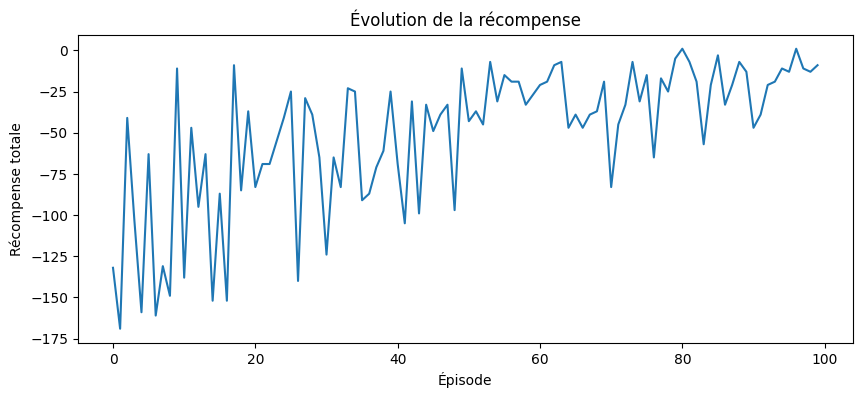

In [20]:
plt.figure(figsize=(10, 4))
plt.plot(episode_rewards)
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")
plt.title("Évolution de la récompense")
plt.show()